In [1]:
import torch
import time
import math
import copy
import random
import logging
import requests
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from tqdm import tqdm
from torch.utils.data import DataLoader
from torchsummary import summary
from typing import Dict, Callable
from PIL import Image
import os
import pandas as pd
import wandb
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

assert torch.cuda.is_available()
device = torch.device("cuda")

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!cp drive/MyDrive/data.zip .
!unzip data.zip

Streaming output truncated to the last 5000 lines.
  inflating: train_images/train_27292.png  
  inflating: train_images/train_07872.png  
  inflating: train_images/train_05588.png  
  inflating: train_images/train_00599.png  
  inflating: train_images/train_34047.png  
  inflating: train_images/train_47902.png  
  inflating: train_images/train_10334.png  
  inflating: train_images/train_40705.png  
  inflating: train_images/train_20845.png  
  inflating: train_images/train_09367.png  
  inflating: train_images/train_42150.png  
  inflating: train_images/train_42617.png  
  inflating: train_images/train_17651.png  
  inflating: train_images/train_12987.png  
  inflating: train_images/train_45000.png  
  inflating: train_images/train_16802.png  
  inflating: train_images/train_19818.png  
  inflating: train_images/train_11662.png  
  inflating: train_images/train_48217.png  
  inflating: train_images/train_02216.png  
  inflating: train_images/train_02474.png  
  inflating: train_images

In [4]:
!cp drive/MyDrive/cifar-10-python.tar.gz .
!tar -xzvf cifar-10-python.tar.gz

cifar-10-batches-py/
cifar-10-batches-py/data_batch_4
cifar-10-batches-py/readme.html
cifar-10-batches-py/test_batch
cifar-10-batches-py/data_batch_3
cifar-10-batches-py/batches.meta
cifar-10-batches-py/data_batch_2
cifar-10-batches-py/data_batch_5
cifar-10-batches-py/data_batch_1


In [5]:
class CIFARDataset(torch.utils.data.Dataset):
    def __init__(self, csv_file, image_dir, transform=None, labeled=True):
        data = pd.read_csv(csv_file)
        self.images = [
          Image.open(os.path.join(image_dir, filename)).convert("RGB")
          for filename in data["filename"]
        ]
        self.labels = data["label"].tolist() if labeled else None
        self.image_dir = image_dir
        self.transform = transform
        self.labeled = labeled

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]
        if self.transform:
            image = self.transform(image)
        if self.labeled:
            return image, self.labels[idx]
        return image


class CIFAR:
    def __init__(self, batch_size=128, num_workers=2):
        self.root = "."
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.train_loader, self.val_loader, self.test_loader = self.prepare_data()

    def prepare_data(self):
        transform_train = transforms.Compose([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(),
            # transforms.AutoAugment(transforms.autoaugment.AutoAugmentPolicy.CIFAR10),
            transforms.TrivialAugmentWide(),
            # transforms.AutoAugment(),
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
            # transforms.RandomErasing(p=0.25, scale=(0.02, 0.2)),
        ])

        transform_test = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
        ])

        trainset = CIFARDataset(
            os.path.join(self.root, "train_labels.csv"),
            os.path.join(self.root, "train_images"),
            transform_train,
        )

        valset = CIFARDataset(
            os.path.join(self.root, "train_labels.csv"),
            os.path.join(self.root, "train_images"),
            transform_test,
        )

        testset = CIFARDataset(
            os.path.join(self.root, "test.csv"),
            os.path.join(self.root, "test_images"),
            transform_test,
            labeled=False,
        )

        train_size = int(0.9 * len(trainset))
        val_size = len(trainset) - train_size

        generator = torch.Generator().manual_seed(42)
        train_indices, val_indices = torch.utils.data.random_split(
            range(len(trainset)), [train_size, val_size], generator=generator
        )

        trainloader = torch.utils.data.DataLoader(
            # torch.utils.data.Subset(trainset, train_indices.indices),
            trainset,
            batch_size=self.batch_size, shuffle=True, num_workers=self.num_workers
        )

        valloader = torch.utils.data.DataLoader(
            torch.utils.data.Subset(valset, val_indices.indices),
            batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers
        )

        testloader = torch.utils.data.DataLoader(
            testset, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers
        )

        return trainloader, valloader, testloader

In [6]:
class BasicBlock(nn.Module):
    """
    BasicBlock is the fundamental building block of ResNet.
    It consists of two 3x3 convolutional layers.
    If the input dimensions do not match the output dimensions,
    or the stride is not 1, a shortcut (identity mapping) is used to adjust dimensions.
    """

    expansion = 1

    def __init__(self, in_planes, planes, stride=1, kernel_size=3, shortcut_kernel_size=1):
        super(BasicBlock, self).__init__()
        # First convolution layer with batch normalization
        self.conv1 = nn.Conv2d(
            in_planes, planes, kernel_size=kernel_size, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(planes)

        # Second convolution layer with batch normalization
        self.conv2 = nn.Conv2d(
            planes, planes, kernel_size=kernel_size, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(planes)

        # Shortcut connection (identity mapping)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_planes,
                    self.expansion * planes,
                    kernel_size=shortcut_kernel_size,
                    stride=stride,
                    bias=False,
                ),
                nn.BatchNorm2d(self.expansion * planes),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        shortcut_out = self.shortcut(x)
        out += shortcut_out
        out = F.relu(out)
        return out


class Bottleneck(nn.Module):
    """
    Bottleneck is the advanced building block used in deeper versions of ResNet (e.g., ResNet-50, ResNet-101).
    It consists of three layers: 1x1 conv, 3x3 conv, and another 1x1 conv.
    The purpose of the bottleneck is to reduce computation by compressing the dimensions before the 3x3 convolution.
    """

    expansion = 4

    def __init__(self, in_planes, planes, stride=1, kernel_size=3, shortcut_kernel_size=1):
        super(Bottleneck, self).__init__()
        # 1x1 convolution to reduce the number of input channels
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)

        # 3x3 convolution for main processing
        self.conv2 = nn.Conv2d(
            planes, planes, kernel_size=kernel_size, stride=stride, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(planes)

        # 1x1 convolution to expand the number of output channels
        self.conv3 = nn.Conv2d(
            planes, self.expansion * planes, kernel_size=1, bias=False
        )
        self.bn3 = nn.BatchNorm2d(self.expansion * planes)

        # Shortcut connection
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_planes,
                    self.expansion * planes,
                    kernel_size=shortcut_kernel_size,
                    stride=stride,
                    bias=False,
                ),
                nn.BatchNorm2d(self.expansion * planes),
            )

    def forward(self, x):
        # Forward pass through the bottleneck block (1x1 -> 3x3 -> 1x1)
        out = F.relu(self.bn1(self.conv1(x)))
        out = F.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))

        # Add the shortcut connection and pass through ReLU again
        out += self.shortcut(x)
        out = F.relu(out)
        return out


class ResNet(nn.Module):
    """
    ResNet class that builds the full ResNet architecture using the BasicBlock or Bottleneck block.
    The number of blocks and layers is determined by the `num_blocks` parameter.
    """

    def __init__(self, block, num_blocks, channels, kernel_size, shortcut_kernel_size, avg_pooling_size, num_classes=10, kaiming=True):
        super(ResNet, self).__init__()
        self.in_planes = channels[0]
        self.kernel_size = kernel_size
        self.shortcut_kernel_size = shortcut_kernel_size
        self.avg_pooling_size = avg_pooling_size

        self.conv1 = nn.Conv2d(3, channels[0], kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels[0])

        # Create the subsequent layers of the network using the blocks
        self.layer1 = self._make_layer(block, channels[0], num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, channels[1], num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, channels[2], num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, channels[3], num_blocks[3], stride=2)

        # Final fully connected layer to classify the output
        self.linear = nn.Linear(channels[3] * block.expansion, num_classes)
        # self.dropout = nn.Dropout(0.2)

        if kaiming:
            for m in self.modules():
                if isinstance(m, nn.Conv2d):
                    nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                elif isinstance(m, nn.BatchNorm2d):
                    nn.init.constant_(m.weight, 1)
                    nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride):
        """
        Creates a residual layer consisting of `num_blocks` residual blocks.
        The first block may have a stride > 1 to downsample the feature maps.
        """
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_planes, planes, stride, self.kernel_size, self.shortcut_kernel_size))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))

        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = F.avg_pool2d(out, self.avg_pooling_size)

        out = out.view(out.size(0), -1)
        # out = self.dropout(out)
        out = self.linear(out)
        return out

def ResNet5M(blocks=[1, 1, 1, 1], channels=[64, 128, 256, 512], kernel_size=3, shortcut_kernel_size=1, avg_pooling_size=4, kaiming=False):
    return ResNet(BasicBlock, blocks, channels, kernel_size, shortcut_kernel_size, avg_pooling_size, kaiming=kaiming)

# def ResNet18():
#     return ResNet(BasicBlock, [2, 2, 2, 2])

# def ResNet34():
#     return ResNet(BasicBlock, [3, 4, 6, 3])

# def ResNet50():
#     return ResNet(Bottleneck, [3, 4, 6, 3])

# def ResNet101():
#     return ResNet(Bottleneck, [3, 4, 23, 3])

# def ResNet152():
#     return ResNet(Bottleneck, [3, 8, 36, 3])

In [7]:
def cutmix_data(x, y, alpha=1.0, p=0.5):
    if np.random.rand() > p:
        return x, y, y, 1.0

    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(x.size(0), device=x.device)

    h, w = x.size(2), x.size(3)

    cut_ratio = np.sqrt(1.0 - lam)
    cut_w = int(w * cut_ratio)
    cut_h = int(h * cut_ratio)

    cx = np.random.randint(w)
    cy = np.random.randint(h)

    x1 = np.clip(cx - cut_w // 2, 0, w)
    x2 = np.clip(cx + cut_w // 2, 0, w)
    y1 = np.clip(cy - cut_h // 2, 0, h)
    y2 = np.clip(cy + cut_h // 2, 0, h)

    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]

    lam = 1 - ((x2 - x1) * (y2 - y1) / (w * h))

    return x, y, y[index], lam

In [8]:
def train(model, train_dataloader, val_dataloader, criterion, optimizer, epochs=10, device="cuda"):
    model = model.to(device)

    # warmup = torch.optim.lr_scheduler.LinearLR(
    #     optimizer,
    #     start_factor=0.1,
    #     end_factor=1.0,
    #     total_iters=5
    # )

    # cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
    #     optimizer,
    #     T_max=epochs - 5,
    #     eta_min=1e-6
    # )

    # scheduler = torch.optim.lr_scheduler.SequentialLR(
    #     optimizer,
    #     schedulers=[warmup, cosine],
    #     milestones=[5]
    # )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=1e-6
    )

    wandb.init(project="deeplearning-resnet-cifar10", config=config)

    best_val_acc = 0.0
    ema_model = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(0.999), use_buffers=True)

    for epoch in range(epochs):
        print(f"\nEpoch: {epoch+1}/{epochs}")
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        with tqdm(total=len(train_dataloader), desc=f"Train Epoch {epoch+1}") as pbar:
            for batch_idx, (inputs, targets) in enumerate(train_dataloader):
                # CutMix
                inputs, targets = inputs.to(device), targets.to(device)
                inputs, targets_a, targets_b, lam = cutmix_data(inputs, targets)

                optimizer.zero_grad()
                outputs = model(inputs)

                loss = (
                    lam * criterion(outputs, targets_a)
                    + (1 - lam) * criterion(outputs, targets_b)
                )
                loss.backward()
                optimizer.step()

                # # Original:
                # inputs, targets = inputs.to(device), targets.to(device)

                # optimizer.zero_grad()
                # outputs = model(inputs)
                # loss = criterion(outputs, targets)
                # loss.backward()
                # optimizer.step()

                ema_model.update_parameters(model)

                train_loss += loss.item()
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()

                pbar.set_postfix(
                    {
                        "Loss": f"{train_loss/(batch_idx+1):.3f}",
                        "Acc": f"{100.0 * correct / total:.3f}%",
                    }
                )
                pbar.update(1)

        epoch_loss = train_loss / len(train_dataloader)
        epoch_acc = 100.0 * correct / total

        # val_acc = evaluate(model, val_dataloader, device)
        val_acc = evaluate(ema_model.module, val_dataloader, device)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            # torch.save(model.state_dict(), "best.pth")
            torch.save(ema_model.module.state_dict(), "best.pth")

        scheduler.step()

        wandb.log({
            "epoch": epoch + 1,
            "train/loss": epoch_loss,
            "train/accuracy": epoch_acc,
            "val/accuracy": val_acc,
            "lr": optimizer.param_groups[0]["lr"],
            "best_val_accuracy": best_val_acc,
        })

        print(
            f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%"
        )

    artifact = wandb.Artifact(
        name=f"resnet-{wandb.run.id}",
        type="model",
        metadata={"best_val_accuracy": best_val_acc, **config},
    )
    artifact.add_file("best.pth")
    wandb.log_artifact(artifact)

    wandb.finish()

    # return model
    return ema_model.module

In [9]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate(model, test_dataloader, device="cuda", confusion=False) -> float:
    model = model.to(device)
    model.eval()

    correct = 0
    total = 0
    y_true, y_pred = [], []
    classes = [
        "airplane", "automobile", "bird", "cat", "deer",
        "dog", "frog", "horse", "ship", "truck"
    ]

    with torch.no_grad():
        for inputs, targets in tqdm(test_dataloader, desc="Evaluating", leave=False):
            # Original:
            #
            # inputs, targets = inputs.to(device), targets.to(device)
            # y = model(inputs)
            # predicted = y.argmax(1)
            # y_true.extend(targets.cpu().numpy())
            # y_pred.extend(y.argmax(dim=1).cpu().numpy())

            # TTA:
            inputs, targets = inputs.to(device), targets.to(device)
            o1 = model(inputs)
            o2 = model(torch.flip(inputs, dims=[3]))
            o = (o1 + o2) / 2
            predicted = o.argmax(dim=1)
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    accuracy = 100. * correct / total

    print(f"Accuracy on the test set: {accuracy:.2f}%")

    if confusion:
        cm = confusion_matrix(y_true, y_pred)

        plt.figure(figsize=(10, 8))
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=[f"{i}: {c}" for i, c in enumerate(classes)],
            yticklabels=[f"{i}: {c}" for i, c in enumerate(classes)]
        )
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()

        print(classification_report(
            y_true,
            y_pred,
            target_names=classes,
            digits=4
        ))

    return accuracy

In [10]:
def evaluate_submit(model, test_dataloader, submission_file="./submission.csv", device="cuda") -> float:
    model = model.to(device)
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        with open(submission_file, "w", encoding="utf-8") as file:
            file.writelines(["id,label\n"])
            idx = 0
            for inputs in tqdm(test_dataloader, desc="Evaluating", leave=False):
                # inputs = inputs.to(device)
                # y = model(inputs)
                # preds = y.argmax(dim=1).cpu().tolist()

                inputs = inputs.to(device)
                o1 = model(inputs)
                o2 = model(torch.flip(inputs, dims=[3]))
                o = (o1 + o2) / 2
                preds= o.argmax(dim=1)

                file.writelines(f"{idx+i},{p}\n" for i, p in enumerate(preds))
                idx += len(preds)

In [11]:
%env WANDB_API_KEY=YOUR_WANDB_API_KEY

In [32]:
config = {
    "architecture": "ResNet5M",
    # "blocks": [1, 1, 1, 1],
    # "channels": [64, 128, 256, 512],
    "kernel_size": 3,
    "shortcut_kernel_size": 1,
    "avg_pooling_size": 4,
    # "blocks": [2, 2, 2, 2], # Base
    # "channels": [64, 128, 232, 268], # Base
    "blocks": [2, 2, 3, 1], # actual
    "channels": [64, 128, 248, 256], # actual
    # "blocks": [4, 4, 4, 1],
    # "channels": [56, 112, 200, 256],
    # "blocks": [2, 2, 2, 2],
    # "channels": [40, 80, 160, 320],
    # "blocks": [2, 4, 4, 3],
    # "channels": [32, 64, 128, 256],
    "batch_size": 128,
    "workers": 2,
    "epochs": 200,
    "optimizer": "SGDNesterov",
    "momentum": 0.9,
    "lr": 0.05,
    "weight_decay": 5e-4,
    "augmentation": "AutoAugment (no erasing)",
    "tta": True,
    "label_smoothing": 0.1,
    "kaiming": True
}

cifar_loader = CIFAR(batch_size=config["batch_size"], num_workers=config["workers"])
dataloader = {}
dataloader['train'], dataloader['val'], dataloader['test'] = cifar_loader.train_loader, cifar_loader.val_loader, cifar_loader.test_loader

model = ResNet5M(blocks=config["blocks"], channels=config["channels"], kaiming=config["kaiming"]).to(device)
summary(model, (3, 32, 32))
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert num_params <= 5_000_000

# if torch.cuda.device_count() > 1:
#     model = nn.DataParallel(model)
criterion = nn.CrossEntropyLoss(label_smoothing=config["label_smoothing"])
# optimizer = optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
optimizer = optim.SGD(model.parameters(), lr=config["lr"], momentum=config["momentum"], weight_decay=config["weight_decay"], nesterov=True)
# train(
#     model=model,
#     train_dataloader=dataloader['train'],
#     # val_dataloader=dataloader['val'],
#     val_dataloader=CIFAROriginal(batch_size=config["batch_size"], num_workers=config["workers"]).test_loader,
#     criterion=criterion,
#     optimizer=optimizer,
#     epochs=config["epochs"],
#     device="cuda"
# )

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
            Conv2d-3           [-1, 64, 32, 32]          36,864
       BatchNorm2d-4           [-1, 64, 32, 32]             128
            Conv2d-5           [-1, 64, 32, 32]          36,864
       BatchNorm2d-6           [-1, 64, 32, 32]             128
        BasicBlock-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          36,864
       BatchNorm2d-9           [-1, 64, 32, 32]             128
           Conv2d-10           [-1, 64, 32, 32]          36,864
      BatchNorm2d-11           [-1, 64, 32, 32]             128
       BasicBlock-12           [-1, 64, 32, 32]               0
           Conv2d-13          [-1, 128, 16, 16]          73,728
      BatchNorm2d-14          [-1, 128,

In [ ]:
import hashlib

def img_hash(img):
    return hashlib.md5(np.asarray(img.convert("RGB")).tobytes()).hexdigest()

root = cifar_loader.root
cifar_test = torchvision.datasets.CIFAR10("./data_original", train=False, download=True)
cifar_test_hashes = {img_hash(img) for img, _ in cifar_test}

for csv, folder in [("train_labels.csv", "train_images"), ("test.csv", "test_images")]:
    df = pd.read_csv(os.path.join(root, csv))
    imgs = [Image.open(os.path.join(root, folder, f)) for f in df["filename"]]
    overlap = sum(img_hash(img) in cifar_test_hashes for img in imgs)
    pixels = np.stack([np.asarray(img.convert("RGB")) for img in imgs]) / 255.0
    print(folder, len(df), "overlap with CIFAR test:", overlap,
          "mean:", pixels.mean((0, 1, 2)).round(4), "std:", pixels.std((0, 1, 2)).round(4))

train_images 50000 overlap with CIFAR test: 0 mean: [0.4914 0.4822 0.4465] std: [0.247  0.2435 0.2616]
test_images 2000 overlap with CIFAR test: 0 mean: [0.513  0.4978 0.4612] std: [0.2648 0.2622 0.2751]


Accuracy on the test set: 100.00%


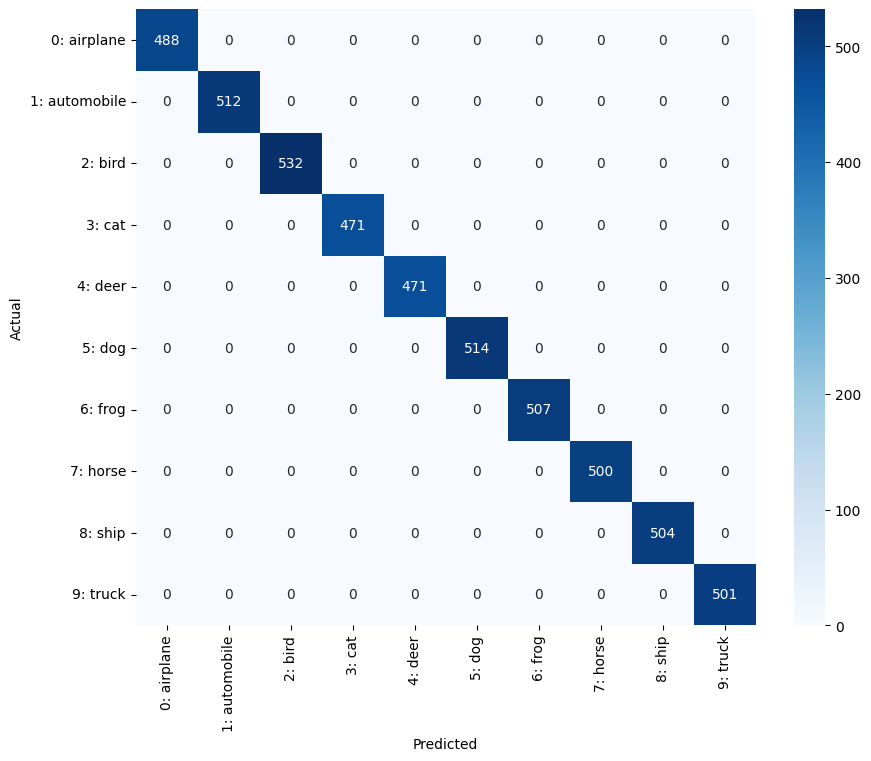

              precision    recall  f1-score   support

    airplane     1.0000    1.0000    1.0000       488
  automobile     1.0000    1.0000    1.0000       512
        bird     1.0000    1.0000    1.0000       532
         cat     1.0000    1.0000    1.0000       471
        deer     1.0000    1.0000    1.0000       471
         dog     1.0000    1.0000    1.0000       514
        frog     1.0000    1.0000    1.0000       507
       horse     1.0000    1.0000    1.0000       500
        ship     1.0000    1.0000    1.0000       504
       truck     1.0000    1.0000    1.0000       501

    accuracy                         1.0000      5000
   macro avg     1.0000    1.0000    1.0000      5000
weighted avg     1.0000    1.0000    1.0000      5000



100.0

In [ ]:
evaluate(
    model=model,
    test_dataloader=dataloader['val'],
    device="cuda",
    confusion=True
)

In [12]:
class CIFAROriginal:
    def __init__(self, batch_size=128, num_workers=2):
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.test_loader = self.prepare_data()

    def prepare_data(self):
        transform_test = transforms.Compose(
            [
                transforms.ToTensor(),
                transforms.Normalize(
                    (0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)
                ),
            ]
        )

        testset = torchvision.datasets.CIFAR10(
            root=".", train=False, download=True, transform=transform_test
        )
        testloader = torch.utils.data.DataLoader(
            testset, batch_size=128, shuffle=False, num_workers=self.num_workers
        )

        return testloader

cifar_original = CIFAROriginal(batch_size=128, num_workers=2)
dataloader_test_original = cifar_original.test_loader
# evaluate(
#     model=model,
#     test_dataloader=dataloader_test_original,
#     device="cuda",
#     confusion=True
# )

In [ ]:
!rm submission.csv
# evaluate_submit(
#     model=model,
#     test_dataloader=dataloader['test'],
#     device="cuda"
# )

rm: cannot remove 'submission.csv': No such file or directory


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_ration

Accuracy on the test set: 97.10%


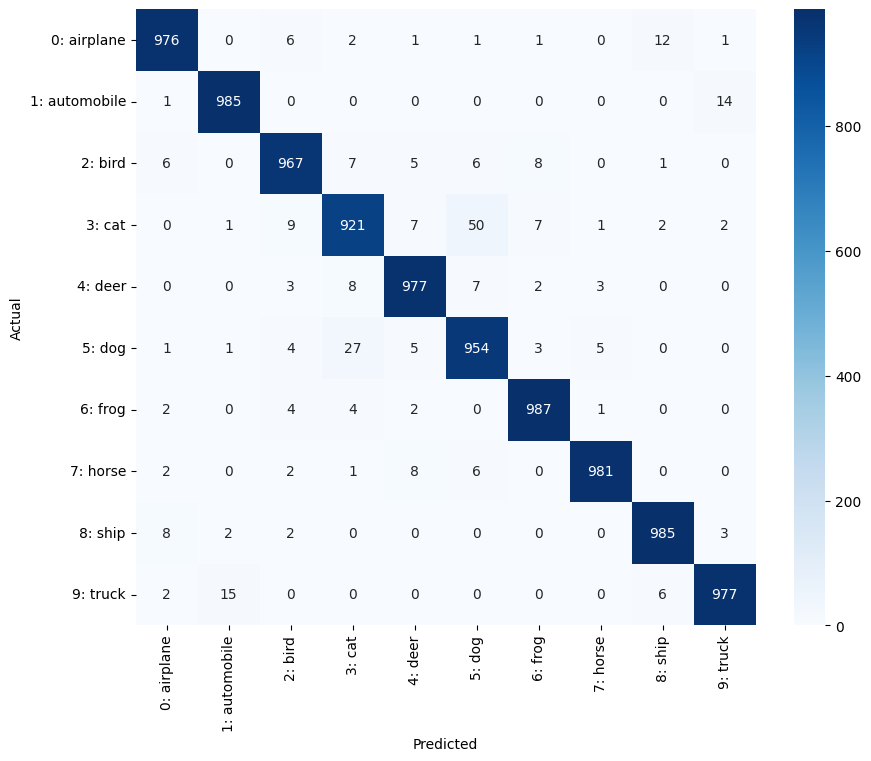

              precision    recall  f1-score   support

    airplane     0.9780    0.9760    0.9770      1000
  automobile     0.9811    0.9850    0.9830      1000
        bird     0.9699    0.9670    0.9685      1000
         cat     0.9495    0.9210    0.9350      1000
        deer     0.9721    0.9770    0.9746      1000
         dog     0.9316    0.9540    0.9427      1000
        frog     0.9792    0.9870    0.9831      1000
       horse     0.9899    0.9810    0.9854      1000
        ship     0.9791    0.9850    0.9821      1000
       truck     0.9799    0.9770    0.9785      1000

    accuracy                         0.9710     10000
   macro avg     0.9710    0.9710    0.9710     10000
weighted avg     0.9710    0.9710    0.9710     10000



In [37]:
loaded_model = ResNet5M(blocks=config["blocks"], channels=config["channels"])

state_dict = torch.load("best_distill.pth", map_location=device, weights_only=True)
state_dict = {k.replace("module.", "", 1): v for k, v in state_dict.items()}

loaded_model.load_state_dict(state_dict)
loaded_model = loaded_model.to(device)

evaluate(loaded_model, CIFAROriginal(batch_size=32, num_workers=4).test_loader, device, confusion=True)

evaluate_submit(
    model=loaded_model,
    test_dataloader=dataloader['test'],
    device="cuda"
)

Accuracy on the test set: 92.30%


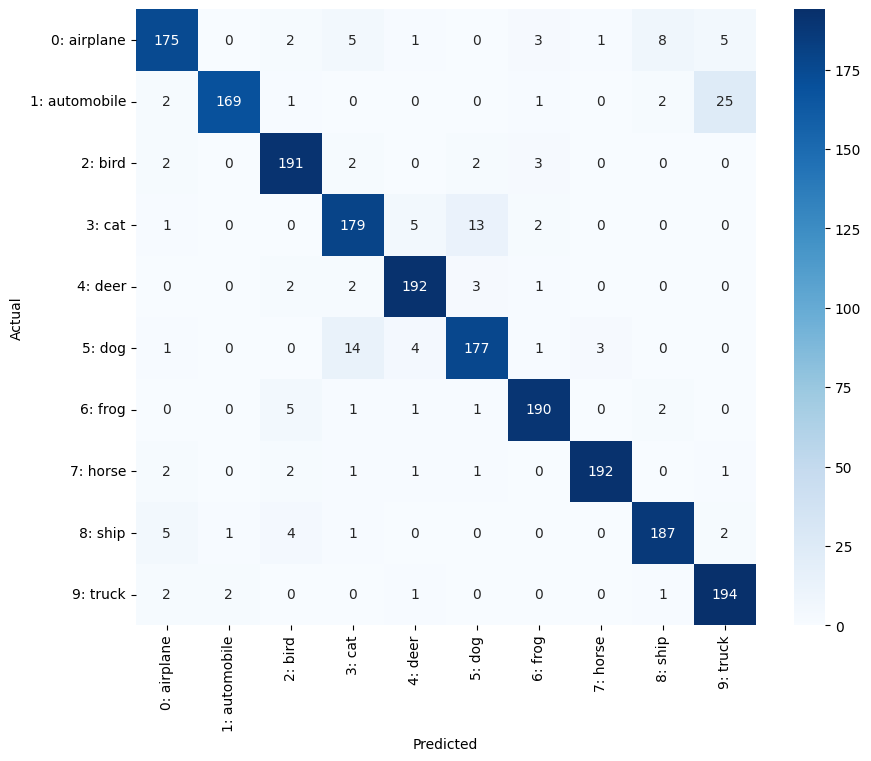

              precision    recall  f1-score   support

    airplane     0.9211    0.8750    0.8974       200
  automobile     0.9826    0.8450    0.9086       200
        bird     0.9227    0.9550    0.9386       200
         cat     0.8732    0.8950    0.8840       200
        deer     0.9366    0.9600    0.9481       200
         dog     0.8985    0.8850    0.8917       200
        frog     0.9453    0.9500    0.9476       200
       horse     0.9796    0.9600    0.9697       200
        ship     0.9350    0.9350    0.9350       200
       truck     0.8546    0.9700    0.9087       200

    accuracy                         0.9230      2000
   macro avg     0.9249    0.9230    0.9229      2000
weighted avg     0.9249    0.9230    0.9229      2000



92.3

In [36]:
# !wget -q https://github.com/modestyachts/CIFAR-10.1/raw/master/datasets/cifar10.1_v6_data.npy
# !wget -q https://github.com/modestyachts/CIFAR-10.1/raw/master/datasets/cifar10.1_v6_labels.npy

class CIFAR101(torch.utils.data.Dataset):
    def __init__(self, transform):
        self.images = np.load("cifar10.1_v6_data.npy")    # (2000, 32, 32, 3) uint8
        self.labels = np.load("cifar10.1_v6_labels.npy").astype(np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.transform(Image.fromarray(self.images[idx])), self.labels[idx]

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])
cifar101_loader = torch.utils.data.DataLoader(
    CIFAR101(transform_test), batch_size=500, shuffle=False, num_workers=2
)

evaluate(loaded_model, cifar101_loader, device, confusion=True)

In [ ]:
import shutil

shutil.copy("best.pth", "best-before-resume.pth")

model = ResNet5M(blocks=config["blocks"], channels=config["channels"], kaiming=config["kaiming"])
state_dict = torch.load("best.pth", map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model = model.to(device)

val_loader = CIFAROriginal(batch_size=config["batch_size"], num_workers=config["workers"]).test_loader

config["epochs"] = 100
config["lr"] = 0.01
config["resumed_from"] = "best.pth"

optimizer = optim.SGD(model.parameters(), lr=config["lr"], momentum=config["momentum"],
                      weight_decay=config["weight_decay"], nesterov=True)
train(
    model=model,
    train_dataloader=dataloader['train'],
    val_dataloader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=config["epochs"],
    device="cuda"
)

best_val_accuracy,▁
epoch,▁
lr,▁
train/accuracy,▁
train/loss,▁
val/accuracy,▁
best_val_accuracy,88.44
epoch,1
lr,0.02
train/accuracy,87.184
train/loss,0.61383



Epoch: 1/100


Train Epoch 1: 100%|██████████| 391/391 [00:55<00:00,  7.09it/s, Loss=0.456, Acc=93.212%]


Accuracy on the test set: 92.85%
Epoch [1/100] - Loss: 0.4562, Accuracy: 93.21%

Epoch: 2/100


Train Epoch 2: 100%|██████████| 391/391 [00:54<00:00,  7.12it/s, Loss=0.472, Acc=92.634%]


Accuracy on the test set: 93.64%
Epoch [2/100] - Loss: 0.4722, Accuracy: 92.63%

Epoch: 3/100


... (68 outputs left out)

Train Epoch 37: 100%|██████████| 391/391 [00:56<00:00,  6.94it/s, Loss=0.406, Acc=95.166%]


Accuracy on the test set: 94.96%
Epoch [37/100] - Loss: 0.4059, Accuracy: 95.17%

Epoch: 38/100


Train Epoch 38:   6%|▋         | 25/391 [00:03<00:57,  6.37it/s, Loss=0.389, Acc=96.125%]


KeyboardInterrupt: 

In [ ]:
class LayerNorm2d(nn.LayerNorm):

    def forward(self, x):
        x = x.permute(0, 2, 3, 1)
        x = super().forward(x)
        return x.permute(0, 3, 1, 2)


class ConvNeXtBlock(nn.Module):

    def __init__(self, dim, kernel_size=7, drop_path=0.0, layer_scale_init=1e-6):
        super(ConvNeXtBlock, self).__init__()
        self.dwconv = nn.Conv2d(dim, dim, kernel_size=kernel_size, padding=kernel_size // 2, groups=dim)
        self.norm = nn.LayerNorm(dim)
        self.pwconv1 = nn.Linear(dim, 4 * dim)
        self.pwconv2 = nn.Linear(4 * dim, dim)
        self.gamma = nn.Parameter(layer_scale_init * torch.ones(dim))
        self.drop_path = drop_path

    def forward(self, x):
        out = self.dwconv(x)
        out = out.permute(0, 2, 3, 1)  # NCHW -> NHWC so LayerNorm/Linear act on channels
        out = self.pwconv2(F.gelu(self.pwconv1(self.norm(out))))
        out = (self.gamma * out).permute(0, 3, 1, 2)

        if self.training and self.drop_path > 0:
            keep = torch.rand(x.size(0), 1, 1, 1, device=x.device) >= self.drop_path
            out = out * keep / (1 - self.drop_path)
        return x + out


class ConvNeXt(nn.Module):

    def __init__(self, depths, dims, kernel_size=7, drop_path=0.1, num_classes=10):
        super(ConvNeXt, self).__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, dims[0], kernel_size=3, stride=1, padding=1),
            LayerNorm2d(dims[0]),
        )

        rates = torch.linspace(0, drop_path, sum(depths)).tolist()
        self.stages = nn.ModuleList()
        self.downsamples = nn.ModuleList()
        idx = 0
        for i, (depth, dim) in enumerate(zip(depths, dims)):
            if i > 0:
                self.downsamples.append(nn.Sequential(
                    LayerNorm2d(dims[i - 1]),
                    nn.Conv2d(dims[i - 1], dim, kernel_size=2, stride=2),
                ))
            self.stages.append(nn.Sequential(
                *[ConvNeXtBlock(dim, kernel_size, rates[idx + j]) for j in range(depth)]
            ))
            idx += depth

        self.norm = nn.LayerNorm(dims[-1])
        self.linear = nn.Linear(dims[-1], num_classes)

        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.trunc_normal_(m.weight, std=0.02)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        out = self.stem(x)
        for i, stage in enumerate(self.stages):
            if i > 0:
                out = self.downsamples[i - 1](out)
            out = stage(out)
        out = out.mean(dim=(2, 3))  # global average pool
        return self.linear(self.norm(out))


def make_optimizer(model, config):
    decay = [p for n, p in model.named_parameters() if p.ndim > 1]
    no_decay = [p for n, p in model.named_parameters() if p.ndim <= 1]
    return optim.AdamW(
        [{"params": decay, "weight_decay": config["weight_decay"]},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=config["lr"],
    )


def train_convnext(model, train_dataloader, val_dataloader, criterion, optimizer, config, epochs=10,
          device="cuda", checkpoint="best_convnext.pth"):
    model = model.to(device)

    warmup_epochs = config.get("warmup_epochs", 5)
    warmup = torch.optim.lr_scheduler.LinearLR(
        optimizer,
        start_factor=0.1,
        end_factor=1.0,
        total_iters=warmup_epochs
    )

    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs - warmup_epochs,
        eta_min=1e-6
    )

    scheduler = torch.optim.lr_scheduler.SequentialLR(
        optimizer,
        schedulers=[warmup, cosine],
        milestones=[warmup_epochs]
    )

    wandb.init(project="deeplearning-resnet-cifar10", config=config)

    best_val_acc = 0.0

    for epoch in range(epochs):
        print(f"\nEpoch: {epoch+1}/{epochs}")
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        with tqdm(total=len(train_dataloader), desc=f"Train Epoch {epoch+1}") as pbar:
            for batch_idx, (inputs, targets) in enumerate(train_dataloader):
                inputs, targets = inputs.to(device), targets.to(device)

                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()

                train_loss += loss.item()
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()

                pbar.set_postfix(
                    {
                        "Loss": f"{train_loss/(batch_idx+1):.3f}",
                        "Acc": f"{100.0 * correct / total:.3f}%",
                    }
                )
                pbar.update(1)

        epoch_loss = train_loss / len(train_dataloader)
        epoch_acc = 100.0 * correct / total

        val_acc = evaluate(model, val_dataloader, device)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), checkpoint)

        scheduler.step()

        wandb.log({
            "epoch": epoch + 1,
            "train/loss": epoch_loss,
            "train/accuracy": epoch_acc,
            "val/accuracy": val_acc,
            "lr": optimizer.param_groups[0]["lr"],
            "best_val_accuracy": best_val_acc,
        })

        print(
            f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%"
        )

    wandb.finish()

    return model


def run_convnext(config, train_dataloader, val_dataloader, device="cuda", checkpoint="best_convnext.pth"):
    model = ConvNeXt(depths=config["depths"], dims=config["dims"], drop_path=config["drop_path"]).to(device)
    summary(model, (3, 32, 32), device=device)
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable parameters: {num_params:,}")
    assert num_params <= 5_000_000

    criterion = nn.CrossEntropyLoss(label_smoothing=config["label_smoothing"])
    optimizer = make_optimizer(model, config)
    return train_convnext(
        model=model,
        train_dataloader=train_dataloader,
        val_dataloader=val_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        config=config,
        epochs=config["epochs"],
        device=device,
        checkpoint=checkpoint,
    )

config = {
    "architecture": "ConvNeXt",
    "depths": [2, 2, 6, 2],
    "dims": [48, 96, 192, 384],
    "drop_path": 0.1,
    "batch_size": 128,
    "epochs": 200,
    "warmup_epochs": 5,
    "optimizer": "AdamW",
    "lr": 1e-3,
    "weight_decay": 0.05,
    "augmentation": "AutoAugment (no erasing)",
    "tta": True,
    "label_smoothing": 0.1,
}

model = run_convnext(
    config,
    train_dataloader=dataloader['train'],
    val_dataloader=CIFAROriginal(batch_size=128, num_workers=2).test_loader,
)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 48, 32, 32]           1,344
       LayerNorm2d-2           [-1, 48, 32, 32]              96
            Conv2d-3           [-1, 48, 32, 32]           2,400
         LayerNorm-4           [-1, 32, 32, 48]              96
            Linear-5          [-1, 32, 32, 192]           9,408
            Linear-6           [-1, 32, 32, 48]           9,264
     ConvNeXtBlock-7           [-1, 48, 32, 32]               0
            Conv2d-8           [-1, 48, 32, 32]           2,400
         LayerNorm-9           [-1, 32, 32, 48]              96
           Linear-10          [-1, 32, 32, 192]           9,408
           Linear-11           [-1, 32, 32, 48]           9,264
    ConvNeXtBlock-12           [-1, 48, 32, 32]               0
      LayerNorm2d-13           [-1, 48, 32, 32]              96
           Conv2d-14           [-1, 96,

wandb: Currently logged in as: ricardotk002 (dl-resnet-2026) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



Epoch: 1/200


Train Epoch 1: 100%|██████████| 391/391 [01:22<00:00,  4.72it/s, Loss=2.169, Acc=20.874%]


Accuracy on the test set: 33.57%
Epoch [1/200] - Loss: 2.1695, Accuracy: 20.87%

Epoch: 2/200


... (395 outputs left out)

Accuracy on the test set: 94.04%
Epoch [199/200] - Loss: 0.5500, Accuracy: 97.84%

Epoch: 200/200


Train Epoch 200: 100%|██████████| 391/391 [01:28<00:00,  4.43it/s, Loss=0.549, Acc=97.836%]
                                                           

Accuracy on the test set: 94.05%
Epoch [200/200] - Loss: 0.5491, Accuracy: 97.84%


best_val_accuracy,▁▃▄▅▆▇▇▇▇▇▇▇▇███████████████████████████
epoch,▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▇▇▇▇▇█████
lr,▃█████▇▇▇▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▄▄▄▄▃▃▂▂▂▂▁▁▁▁▁
train/accuracy,▁▃▅▆▆▇▇▇▇▇▇▇▇███████████████████████████
train/loss,█▆▅▄▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/accuracy,▁▃▆▆▇▇▇▇▇▇▇▇▇███████████████████████████
best_val_accuracy,94.05
epoch,200
lr,0.0
train/accuracy,97.836
train/loss,0.54913


In [15]:
# model = ResNet5M(blocks=config["blocks"], channels=config["channels"], kaiming=config["kaiming"])
loaded_conv = ConvNeXt(depths=config["depths"], dims=config["dims"], drop_path=config["drop_path"]).to(device)

state_dict = torch.load("best_convnext.pth", map_location=device, weights_only=True)
state_dict = {k.replace("module.", "", 1): v for k, v in state_dict.items()}

loaded_conv.load_state_dict(state_dict)
loaded_conv = loaded_conv.to(device)

evaluate(loaded_conv, CIFAROriginal(batch_size=32, num_workers=4).test_loader, device, confusion=True)

# evaluate_submit(
#     model=loaded_conv,
#     test_dataloader=dataloader['test'],
#     device="cuda"
# )

NameError: name 'ConvNeXt' is not defined

In [ ]:
class WideBasic(nn.Module):
    def __init__(self, in_planes, planes, dropout_rate, stride=1):
        super(WideBasic, self).__init__()
        self.bn1 = nn.BatchNorm2d(in_planes)
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, padding=1, bias=False)
        self.dropout = nn.Dropout(p=dropout_rate)
        self.bn2 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
            )

    def forward(self, x):
        out = self.dropout(self.conv1(F.relu(self.bn1(x))))
        out = self.conv2(F.relu(self.bn2(out)))
        out += self.shortcut(x)
        return out


class WideResNet(nn.Module):

    def __init__(self, depth, widen_factor, dropout_rate=0.0, num_classes=10):
        super(WideResNet, self).__init__()
        assert (depth - 4) % 6 == 0, "Wide-resnet depth should be 6n+4"
        n = (depth - 4) // 6
        k = widen_factor
        stages = [16, 16 * k, 32 * k, 64 * k]
        self.in_planes = stages[0]

        self.conv1 = nn.Conv2d(3, stages[0], kernel_size=3, stride=1, padding=1, bias=False)
        self.layer1 = self._wide_layer(stages[1], n, dropout_rate, stride=1)
        self.layer2 = self._wide_layer(stages[2], n, dropout_rate, stride=2)
        self.layer3 = self._wide_layer(stages[3], n, dropout_rate, stride=2)
        self.bn1 = nn.BatchNorm2d(stages[3])
        self.linear = nn.Linear(stages[3], num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _wide_layer(self, planes, num_blocks, dropout_rate, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for stride in strides:
            layers.append(WideBasic(self.in_planes, planes, dropout_rate, stride))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x):
        out = self.conv1(x)
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = F.relu(self.bn1(out))
        out = F.avg_pool2d(out, 8)
        out = out.view(out.size(0), -1)
        return self.linear(out)


config = {
    "architecture": "WideResNet5M",
    "batch_size": 128,
    "workers": 2,
    "epochs": 200,
    "optimizer": "SGDNesterov",
    "momentum": 0.9,
    "lr": 0.05,
    "weight_decay": 5e-4,
    "augmentation": "AutoAugment (no erasing)",
    "tta": True,
    "label_smoothing": 0.05,
    "kaiming": True
}

cifar_loader = CIFAR(batch_size=config["batch_size"], num_workers=config["workers"])
dataloader = {}
dataloader['train'], dataloader['val'], dataloader['test'] = cifar_loader.train_loader, cifar_loader.val_loader, cifar_loader.test_loader

model = WideResNet(depth=22, widen_factor=4, dropout_rate=0.0).to(device)
summary(model, (3, 32, 32))
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert num_params <= 5_000_000

criterion = nn.CrossEntropyLoss(label_smoothing=config["label_smoothing"])
optimizer = optim.SGD(model.parameters(), lr=config["lr"], momentum=config["momentum"], weight_decay=config["weight_decay"], nesterov=True)
train(
    model=model,
    train_dataloader=dataloader['train'],
    # val_dataloader=dataloader['val'],
    val_dataloader=CIFAROriginal(batch_size=config["batch_size"], num_workers=config["workers"]).test_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=config["epochs"],
    device="cuda"
)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 32, 32]             432
       BatchNorm2d-2           [-1, 16, 32, 32]              32
            Conv2d-3           [-1, 64, 32, 32]           9,216
           Dropout-4           [-1, 64, 32, 32]               0
       BatchNorm2d-5           [-1, 64, 32, 32]             128
            Conv2d-6           [-1, 64, 32, 32]          36,864
            Conv2d-7           [-1, 64, 32, 32]           1,024
         WideBasic-8           [-1, 64, 32, 32]               0
       BatchNorm2d-9           [-1, 64, 32, 32]             128
           Conv2d-10           [-1, 64, 32, 32]          36,864
          Dropout-11           [-1, 64, 32, 32]               0
      BatchNorm2d-12           [-1, 64, 32, 32]             128
           Conv2d-13           [-1, 64, 32, 32]          36,864
        WideBasic-14           [-1, 64,


Epoch: 1/200


Train Epoch 1: 100%|██████████| 391/391 [01:16<00:00,  5.08it/s, Loss=1.755, Acc=38.672%]


Accuracy on the test set: 23.78%
Epoch [1/200] - Loss: 1.7553, Accuracy: 38.67%

Epoch: 2/200


Train Epoch 2: 100%|██████████| 391/391 [01:22<00:00,  4.75it/s, Loss=1.356, Acc=56.648%]


Accuracy on the test set: 37.60%
Epoch [2/200] - Loss: 1.3555, Accuracy: 56.65%

Epoch: 3/200


... (24 outputs left out)

Train Epoch 15: 100%|██████████| 391/391 [01:22<00:00,  4.77it/s, Loss=0.753, Acc=81.860%]


Accuracy on the test set: 85.04%
Epoch [15/200] - Loss: 0.7535, Accuracy: 81.86%

Epoch: 16/200


Train Epoch 16:  30%|███       | 118/391 [00:25<00:58,  4.67it/s, Loss=0.730, Acc=82.846%]


KeyboardInterrupt: 

In [33]:
def kd_loss(student_logits, teacher_logits, temperature):
    return F.kl_div(
        F.log_softmax(student_logits / temperature, dim=1),
        F.softmax(teacher_logits / temperature, dim=1),
        reduction="batchmean",
    ) * temperature ** 2


def train_distill(student, teacher, train_dataloader, val_dataloader, optimizer, epochs=300,
                  temperature=4.0, kd_weight=0.9, label_smoothing=0.05, cutmix=True,
                  device="cuda", checkpoint="best_distill.pth"):
    student = student.to(device)
    teacher = teacher.to(device).eval()
    for p in teacher.parameters():
        p.requires_grad_(False)

    ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    print(f"Teacher accuracy on val:")
    teacher_acc = evaluate(teacher, val_dataloader, device)

    run = wandb.init(project="deeplearning-resnet-cifar10",
                     config={**config, "teacher_acc": teacher_acc, "temperature": temperature,
                             "kd_weight": kd_weight, "cutmix": cutmix})
    best_val_acc = 0.0

    for epoch in range(epochs):
        print(f"\nEpoch: {epoch+1}/{epochs}")
        student.train()
        train_loss = 0.0
        correct = 0
        total = 0

        with tqdm(total=len(train_dataloader), desc=f"Train Epoch {epoch+1}") as pbar:
            for batch_idx, (inputs, targets) in enumerate(train_dataloader):
                inputs, targets = inputs.to(device), targets.to(device)
                if cutmix:
                    inputs, targets_a, targets_b, lam = cutmix_data(inputs, targets)
                else:
                    targets_a, targets_b, lam = targets, targets, 1.0

                with torch.no_grad():
                    t_logits = (teacher(inputs) + teacher(torch.flip(inputs, dims=[3]))) / 2

                optimizer.zero_grad()
                outputs = student(inputs)
                hard = lam * ce(outputs, targets_a) + (1 - lam) * ce(outputs, targets_b)
                soft = kd_loss(outputs, t_logits, temperature)
                loss = kd_weight * soft + (1 - kd_weight) * hard
                loss.backward()
                optimizer.step()

                train_loss += loss.item()
                total += targets.size(0)
                correct += outputs.argmax(1).eq(targets_a).sum().item()

                pbar.set_postfix({"Loss": f"{train_loss/(batch_idx+1):.3f}",
                                  "Acc": f"{100.0 * correct / total:.3f}%"})
                pbar.update(1)

        val_acc = evaluate(student, val_dataloader, device)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(student.state_dict(), checkpoint)

        scheduler.step()
        run.log({
            "epoch": epoch + 1,
            "train/loss": train_loss / len(train_dataloader),
            "train/accuracy": 100.0 * correct / total,
            "val/accuracy": val_acc,
            "lr": optimizer.param_groups[0]["lr"],
            "best_val_accuracy": best_val_acc,
        })

    artifact = wandb.Artifact(name=f"resnet-distill-{run.id}", type="model",
                              metadata={"best_val_accuracy": best_val_acc, "teacher_acc": teacher_acc})
    artifact.add_file(checkpoint)
    run.log_artifact(artifact)
    run.finish()

    return student

teacher = ResNet5M(blocks=config["blocks"], channels=config["channels"])
sd = torch.load("best-cutmix.pth", map_location=device, weights_only=True)
teacher.load_state_dict({k.replace("module.", "", 1): v for k, v in sd.items()})

student = ResNet5M(blocks=config["blocks"], channels=config["channels"], kaiming=config["kaiming"]).to(device)
optimizer = optim.SGD(student.parameters(), lr=config["lr"], momentum=config["momentum"], weight_decay=config["weight_decay"], nesterov=True)

student = train_distill(
    student, teacher,
    train_dataloader=dataloader['train'],
    val_dataloader=CIFAROriginal(batch_size=config["batch_size"], num_workers=config["workers"]).test_loader,
    optimizer=optimizer,
    epochs=config["epochs"],
    temperature=4.0, kd_weight=0.9,
    cutmix=True,
)

Teacher accuracy on val:


Accuracy on the test set: 97.08%


best_val_accuracy,▁▂▅▇████████
epoch,▁▂▂▃▄▄▅▅▆▇▇█
lr,███▇▇▆▆▅▄▃▂▁
train/accuracy,▁▄▄▅▆▆▇▇▇▇██
train/loss,█▆▅▄▃▃▃▂▂▂▁▁
val/accuracy,▁▂▅▇███▇▆▅▄▄
best_val_accuracy,52.56
epoch,12
lr,0.09911
train/accuracy,52.092
train/loss,1.52483



Epoch: 1/200


Train Epoch 1: 100%|██████████| 391/391 [01:17<00:00,  5.02it/s, Loss=1.000, Acc=30.292%]


Accuracy on the test set: 47.61%

Epoch: 2/200


... (395 outputs left out)

Accuracy on the test set: 97.10%

Epoch: 200/200


Train Epoch 200: 100%|██████████| 391/391 [01:22<00:00,  4.73it/s, Loss=0.116, Acc=82.134%]


Accuracy on the test set: 97.01%


best_val_accuracy,▁▂▃▄▄▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇█████████████
epoch,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇█
lr,███▇▇▇▇▇▇▇▇▆▆▆▆▆▅▅▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁
train/accuracy,▁▃▄▄▄▄▅▅▅▅▅▅▅▅▆▅▆▆▆▆▆▆▆▆▆▇▆▇▇▇▇▇▇███▇███
train/loss,█▇▆▆▆▆▅▅▅▅▄▄▄▄▄▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
val/accuracy,▁▄▄▄▅▅▆▅▆▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇█████████████
best_val_accuracy,97.1
epoch,200
lr,0.0
train/accuracy,82.134
train/loss,0.11623


In [ ]:
class SqueezeExcite(nn.Module):

    def __init__(self, channels, reduction=16):
        super(SqueezeExcite, self).__init__()
        self.fc1 = nn.Conv2d(channels, channels // reduction, kernel_size=1)
        self.fc2 = nn.Conv2d(channels // reduction, channels, kernel_size=1)

    def forward(self, x):
        w = F.adaptive_avg_pool2d(x, 1)
        w = torch.sigmoid(self.fc2(F.relu(self.fc1(w))))
        return x * w


class SEBasicBlock(BasicBlock):

    def __init__(self, in_planes, planes, stride=1, kernel_size=3, shortcut_kernel_size=1):
        super(SEBasicBlock, self).__init__(in_planes, planes, stride, kernel_size, shortcut_kernel_size)
        self.se = SqueezeExcite(planes)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.se(self.bn2(self.conv2(out)))
        return F.relu(out + self.shortcut(x))


def SEResNet5M(blocks=[2, 2, 3, 1], channels=[64, 128, 244, 252], kernel_size=3, shortcut_kernel_size=1,
               avg_pooling_size=4, kaiming=True):
    return ResNet(SEBasicBlock, blocks, channels, kernel_size, shortcut_kernel_size, avg_pooling_size, kaiming=kaiming)


def train_se(model, train_dataloader, val_dataloader, criterion, optimizer, config, epochs=300,
             device="cuda", checkpoint="best_se.pth"):
    model = model.to(device)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    run = wandb.init(project="deeplearning-resnet-cifar10", config=config)
    best_val_acc = 0.0

    for epoch in range(epochs):
        print(f"\nEpoch: {epoch+1}/{epochs}")
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        with tqdm(total=len(train_dataloader), desc=f"Train Epoch {epoch+1}") as pbar:
            for batch_idx, (inputs, targets) in enumerate(train_dataloader):
                inputs, targets = inputs.to(device), targets.to(device)

                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()

                train_loss += loss.item()
                total += targets.size(0)
                correct += outputs.argmax(1).eq(targets).sum().item()

                pbar.set_postfix({"Loss": f"{train_loss/(batch_idx+1):.3f}",
                                  "Acc": f"{100.0 * correct / total:.3f}%"})
                pbar.update(1)

        val_acc = evaluate(model, val_dataloader, device)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), checkpoint)

        scheduler.step()
        run.log({
            "epoch": epoch + 1,
            "train/loss": train_loss / len(train_dataloader),
            "train/accuracy": 100.0 * correct / total,
            "val/accuracy": val_acc,
            "lr": optimizer.param_groups[0]["lr"],
            "best_val_accuracy": best_val_acc,
        })

    artifact = wandb.Artifact(name=f"se-resnet-{run.id}", type="model",
                              metadata={"best_val_accuracy": best_val_acc})
    artifact.add_file(checkpoint)
    run.log_artifact(artifact)
    run.finish()

    return model

se_config = {**config, "architecture": "SEResNet5M", "channels": [64, 128, 244, 252], "attention": "se"}

model = SEResNet5M(blocks=se_config["blocks"], channels=se_config["channels"], kaiming=se_config["kaiming"]).to(device)
summary(model, (3, 32, 32))
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_params:,}")
assert num_params <= 5_000_000

criterion = nn.CrossEntropyLoss(label_smoothing=se_config["label_smoothing"])
optimizer = optim.SGD(model.parameters(), lr=se_config["lr"], momentum=se_config["momentum"],
                      weight_decay=se_config["weight_decay"], nesterov=True)

model = train_se(
    model,
    train_dataloader=dataloader['train'],
    val_dataloader=CIFAROriginal(batch_size=se_config["batch_size"], num_workers=se_config["workers"]).test_loader,
    criterion=criterion,
    optimizer=optimizer,
    config=se_config,
    epochs=se_config["epochs"],
)